# 05 Design 1 — Reader Omission Detection Diagnostic

- **Question:** Can goal-oriented LLM readers (`deepseek-v4-flash`, `qwen3.5-397b`) catch silent income omissions (`$0` vs `not provided`) across four file-trace levels (`none`, `budget_gap`, `net_deposits`, `wage_match`) without raising false flags on paired truthful twins, and how do they compare against `frozen_checker` and `checker_plus_2_rules`?
- **Expected:** On Level 1 (`none`), `$0` omissions are indistinguishable from truthful `$0` twins so net separation must be ~0. On Levels 2–4 (`budget_gap`, `net_deposits`, `wage_match`), `frozen_checker` catches 0/12 `$0` omissions (and 12/12 `not_provided` omissions including Level 1), while `checker_plus_2_rules` achieves 100% hit rate on Levels 2–4 with 0% twin FPR. LLM readers with goal-oriented omission instructions are tested for whether they exploit budget gaps, recurring deposits (clear vs ambiguous), and cross-match leads while maintaining low twin FPR.
- **Method:** 12 pilot households (5 `earned` targets, 7 `unearned` targets; all with verified shelter > remaining income, target bank deposits, and omission benefit impact > $56) x 4 trace levels x 3 states (`omission_zero`, `omission_not_provided`, `truthful_twin`) = 144 reader inputs, read at `temperature=0`, `max_output_tokens=8192`, `concurrency=8` with forced `report_flags(confidence=True)`. Pre-LLM verification gates and deterministic baselines (`frozen_checker`, `checker_plus_2_rules`) are re-verified here; no model calls are made inside this notebook.
- **Result:** All 288 LLM calls completed cleanly (`288/288` valid, 0 truncated, 6 retries on `qwen3.5-397b`, 7.9 min wall, 0.7510 credits). Deterministic baselines matched design: `frozen_checker` hit `0/12` on `$0` omissions and `12/12` on `not_provided` across all levels (`0/12` twin FPR), while `checker_plus_2_rules` hit `12/12` (`100%`) across Levels 2–4 on both `$0` and `not_provided` (`0/12` twin FPR). Goal-oriented LLMs succeeded on Level 4 (`wage_match`, `12/12` exact hit for both models) and Level 3 `clear` (`6/6` exact hit, `0/6` twin FPR for both), largely failed Level 2 (`budget_gap`: `deepseek-v4-flash` `0/12` on both markers; `qwen3.5-397b` `0/12` on `$0` and `2/12` exact / `3/12` any-income on `not_provided`), and suffered `4/6` (`66.7%`) twin FPR on Level 3 `ambiguous` (single `ACH CREDIT ELECTRONIC TRANSFER` flagged as income). Pooled across Levels 2–4, both LLMs outperformed `frozen_checker` on `$0` omissions (`+0.5278` `[0.3889, 0.6389]` net separation for `deepseek-v4-flash`, `+0.3889` `[0.2222, 0.5556]` for `qwen3.5-397b`), but trailed `checker_plus_2_rules` on both `$0` (`-0.4722` and `-0.6111`) and `not_provided` (`-0.4722` and `-0.5556`).
- **Mismatch:** Expected goal-oriented instructions to enable budget-gap and abstain (`not_provided`) omission detection while keeping twin FPR low; instead: (1) `deepseek-v4-flash` scored `0/24` on `budget_gap` and `qwen3.5-397b` cited the budget gap explicitly on only `2/24` omissions (`14542`, which flagged the wrong income group `unearned`, and `30269`); (2) LLMs mostly ignored the `"not provided"` marker (`0/12` on Level 1 `none`; paired `not_provided - $0` diff `0.0` overall on `deepseek-v4-flash` and `+0.0556` exact on `qwen3.5-397b` L2–L4); (3) both models flagged single non-recurring `ACH CREDIT ELECTRONIC TRANSFER` twin deposits at `4/6` (`66.7%`), and mislabeled ambiguous `$0`-both `unearned` recurring deposits as `earned` (`deepseek-v4-flash` `1/6` on `$0` and `1/6` on `not_provided`; `qwen3.5-397b` `2/6` on both); (4) `qwen3.5-397b` raised spurious `$0` `shelter`/`utilities` twin false flags on `4/12` (`33.3%`) Level 4 twins and `1/12` Level 1 twins (`28066`, which also miscalculated biweekly `$177.67` pay).
- **Feeds:** `rq.md` RQ1 (accuracy of LLM readers vs deterministic rules on silent omissions and abstention markers), RQ2 (failure modes motivating rule-augmented / structured verification).

Code: [`experiments/design1/run_design1.py`](../../experiments/design1/run_design1.py), [`src/snapqc/checker.py`](../../src/snapqc/checker.py), [`src/snapqc/pilot_score.py`](../../src/snapqc/pilot_score.py).

## 0. Setup and Data Loading

In [1]:
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from snapqc import checker as C
from snapqc import forms as F
from snapqc import packets as P
from snapqc.data import ROOT, results_dir

DESIGN1 = ROOT / "experiments" / "design1"
OUT = results_dir("05-design1-reader-omissions")
SEED = 20261114

_spec = importlib.util.spec_from_file_location("run_design1", DESIGN1 / "run_design1.py")
D1 = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(D1)

hh, pk = D1.load_pilot_data()
inputs = D1.read_jsonl(DESIGN1 / "inputs.jsonl")
raw_results = D1.read_jsonl(DESIGN1 / "results.jsonl")
llm_recs = list(D1.latest(raw_results).values())

print(f"Inputs loaded: {len(inputs)} | Raw LLM records: {len(raw_results)} | Final LLM jobs: {len(llm_recs)}")

Inputs loaded: 144 | Raw LLM records: 288 | Final LLM jobs: 288


## 1. Pre-LLM Verification Gates and Design Matrix

Re-verify all 144 inputs: no metadata (`sources`, `missing_facts`), zero leak-regex hits, sequential `doc-01..doc-NN` numbering, format guard on application lines, benefit impact of omitting `target` > $56 for all 12 households, Level 2 housing outflows > reported income for 12/12 omissions (and <= for 12/12 twins), and the 6 clear / 6 ambiguous Level 3 split.

In [2]:
D1.verify_inputs(inputs, hh)

design_rows = []
for row in D1.ALL_ROWS:
    h = hh[row]
    tg = D1.HOUSEHOLD_TARGETS[row]
    l2_om = next(x for x in inputs if x["row"] == row and x["trace_level"] == "budget_gap" and x["state"] == "omission_zero")
    docs = l2_om["packet"]["documents"]
    lease_rent = sum(d["data"]["Monthly rent"] for d in docs if d["kind"] == "lease")
    util_bills = sum(d["data"]["Amount due"] for d in docs if d["kind"] == "utility_bill")
    rem_inc = l2_om["app_monthly"]["earned"] + l2_om["app_monthly"]["unearned"]
    design_rows.append({
        "row": row,
        "state": h["state"],
        "orig_kind": h["kind"],
        "target_group": tg,
        "l3_clarity": "clear" if row in D1.L3_CLEAR else "ambiguous",
        "verified_earned": h["verified_earned"],
        "verified_unearned": h["verified_unearned"],
        "verified_shelter": h["verified_shelter"],
        "verified_utilities": h["verified_utilities"],
        "remaining_income": rem_inc,
        "l2_lease_plus_bills": round(lease_rent + util_bills, 2),
        "omission_impact": l2_om["omission_impact"],
    })
design_df = pd.DataFrame(design_rows)
design_df.to_csv(OUT / "1-households.csv", index=False)
assert (design_df["verified_shelter"] > design_df["remaining_income"]).all()
assert (design_df["omission_impact"] > 56).all()
assert (design_df["l2_lease_plus_bills"] > design_df["remaining_income"]).all()
design_df

ALL 144 INPUT VERIFICATION ASSERTIONS PASSED.


,row,state,orig_kind,target_group,l3_clarity,verified_earned,verified_unearned,verified_shelter,verified_utilities,remaining_income,l2_lease_plus_bills,omission_impact
0,5744,Vermont,error,earned,clear,1646,100,900,1020,100.0,1101.82,162.0
1,14542,Georgia,error,earned,clear,4167,0,1250,415,0.0,1419.06,512.0
2,28402,Louisiana,error,earned,clear,1161,664,800,0,664.0,800.00,384.0
3,42865,Nevada,error,earned,ambiguous,2534,0,600,412,0.0,783.29,515.0
4,42777,Nevada,comparison,earned,ambiguous,3484,1061,1589,412,1061.0,1756.06,748.0
5,28066,Arkansas,error,unearned,clear,382,943,650,0,382.0,650.00,268.0
6,30966,Oklahoma,error,unearned,clear,0,1035,450,388,0.0,618.09,126.0
7,21739,Iowa,error,unearned,clear,0,1716,500,530,0.0,759.75,312.0
8,43456,Oregon,error,unearned,ambiguous,0,3491,1475,469,0.0,1621.21,268.0
9,41978,Nevada,error,unearned,ambiguous,0,1039,200,0,0.0,200.00,211.0


## 2. LLM Call Health (Validity, Tokens, Latency, Credits)

In [3]:
calls_df = pd.DataFrame(llm_recs)
calls_df["truncated"] = [
    r.get("status") == "incomplete" or (r.get("incomplete_details") or {}).get("reason") == "max_output_tokens"
    for r in llm_recs
]
call_summary = calls_df.groupby("reader").agg(
    calls=("job_id", "size"),
    ok_http=("ok_http", "sum"),
    valid=("valid", "sum"),
    truncated=("truncated", "sum"),
    retries=("retries", "sum"),
    input_tokens=("input_tokens", "sum"),
    output_tokens=("output_tokens", "sum"),
    reasoning_tokens=("reasoning_tokens", "sum"),
    median_output_tokens=("output_tokens", "median"),
    median_latency_s=("latency_s", "median"),
    credits=("cost", "sum"),
).reindex(D1.MODELS)
call_summary["valid_rate"] = (call_summary["valid"] / call_summary["calls"]).round(4)
call_summary.to_csv(OUT / "2-call-health.csv")
print("Wall time (min):", round((calls_df["t_end"].max() - calls_df["t_start"].min()) / 60, 2))
invalid_rows = calls_df[~calls_df["valid"].astype(bool)][["job_id", "reader", "status", "invalid_reason"]]
if len(invalid_rows):
    print("Invalid calls:")
    display(invalid_rows)
call_summary

Wall time (min): 7.94


,calls,ok_http,valid,truncated,retries,input_tokens,output_tokens,reasoning_tokens,median_output_tokens,median_latency_s,credits,valid_rate
reader,,,,,,,,,,,,
deepseek-v4-flash,144,144,144,0,0,168718,128837,119133,705.0,5.583,0.020962,1.0
qwen3.5-397b,144,144,144,0,6,170742,181751,173341,1031.0,13.117,0.730037,1.0


## 3. Core Scoring: Hit Rates, Truthful-Twin FPR, and Net Separation

In [4]:
df_eval = D1.evaluate_all_readers(inputs, hh, llm_recs)
df_eval.to_csv(OUT / "3-per-input-eval.csv", index=False)

summary = D1.build_summary_table(df_eval)
summary.to_csv(DESIGN1 / "summary.csv", index=False)
summary.to_csv(OUT / "3-summary.csv", index=False)

all_cells = summary[summary["subset"] == "all"].copy()
l3_cells = summary[summary["subset"] != "all"].copy()

print("=== Summary: All Households (n=12 per cell) ===")
display(all_cells[[
    "reader", "trace_level", "marker",
    "exact_target_hit", "any_income_hit", "twin_any_fpr", "twin_income_fpr",
    "net_sep_exact_vs_any_fpr", "net_sep_any_vs_any_fpr",
]])

print("=== Summary: Level 3 Clear (n=6) vs Ambiguous (n=6) ===")
display(l3_cells[[
    "reader", "subset", "marker",
    "exact_target_hit", "any_income_hit", "twin_any_fpr", "twin_income_fpr",
    "net_sep_exact_vs_any_fpr", "net_sep_any_vs_any_fpr",
]])

=== Summary: All Households (n=12 per cell) ===


,reader,trace_level,marker,exact_target_hit,any_income_hit,twin_any_fpr,twin_income_fpr,net_sep_exact_vs_any_fpr,net_sep_any_vs_any_fpr
0,frozen_checker,none,$0,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
1,frozen_checker,none,not_provided,1.0000,1.00,0.0000,0.0000,1.0000,1.0000
2,frozen_checker,budget_gap,$0,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
3,frozen_checker,budget_gap,not_provided,1.0000,1.00,0.0000,0.0000,1.0000,1.0000
4,frozen_checker,net_deposits,$0,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
5,frozen_checker,net_deposits,not_provided,1.0000,1.00,0.0000,0.0000,1.0000,1.0000
10,frozen_checker,wage_match,$0,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
11,frozen_checker,wage_match,not_provided,1.0000,1.00,0.0000,0.0000,1.0000,1.0000
12,checker_plus_2_rules,none,$0,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
13,checker_plus_2_rules,none,not_provided,1.0000,1.00,0.0000,0.0000,1.0000,1.0000


=== Summary: Level 3 Clear (n=6) vs Ambiguous (n=6) ===


,reader,subset,marker,exact_target_hit,any_income_hit,twin_any_fpr,twin_income_fpr,net_sep_exact_vs_any_fpr,net_sep_any_vs_any_fpr
6,frozen_checker,clear,$0,0.0000,0.0,0.0000,0.0000,0.0000,0.0000
7,frozen_checker,clear,not_provided,1.0000,1.0,0.0000,0.0000,1.0000,1.0000
8,frozen_checker,ambiguous,$0,0.0000,0.0,0.0000,0.0000,0.0000,0.0000
9,frozen_checker,ambiguous,not_provided,1.0000,1.0,0.0000,0.0000,1.0000,1.0000
18,checker_plus_2_rules,clear,$0,1.0000,1.0,0.0000,0.0000,1.0000,1.0000
19,checker_plus_2_rules,clear,not_provided,1.0000,1.0,0.0000,0.0000,1.0000,1.0000
20,checker_plus_2_rules,ambiguous,$0,1.0000,1.0,0.0000,0.0000,1.0000,1.0000
21,checker_plus_2_rules,ambiguous,not_provided,1.0000,1.0,0.0000,0.0000,1.0000,1.0000
30,deepseek-v4-flash,clear,$0,1.0000,1.0,0.0000,0.0000,1.0000,1.0000
31,deepseek-v4-flash,clear,not_provided,1.0000,1.0,0.0000,0.0000,1.0000,1.0000


### 3a. Pivot Tables by Reader x Trace Level x Marker

In [5]:
READER_ORDER = ["frozen_checker", "checker_plus_2_rules", *D1.MODELS]
LEVEL_ORDER = D1.TRACE_LEVELS

pivot_exact = all_cells.pivot(index=["trace_level", "marker"], columns="reader", values="exact_target_hit").reindex(
    pd.MultiIndex.from_product([LEVEL_ORDER, ["$0", "not_provided"]], names=["trace_level", "marker"])
)[READER_ORDER]
pivot_any = all_cells.pivot(index=["trace_level", "marker"], columns="reader", values="any_income_hit").reindex(
    pd.MultiIndex.from_product([LEVEL_ORDER, ["$0", "not_provided"]], names=["trace_level", "marker"])
)[READER_ORDER]
pivot_fpr = all_cells[all_cells["marker"] == "$0"].pivot(index="trace_level", columns="reader", values="twin_any_fpr").reindex(LEVEL_ORDER)[READER_ORDER]
pivot_fpr_inc = all_cells[all_cells["marker"] == "$0"].pivot(index="trace_level", columns="reader", values="twin_income_fpr").reindex(LEVEL_ORDER)[READER_ORDER]
pivot_net_exact = all_cells.pivot(index=["trace_level", "marker"], columns="reader", values="net_sep_exact_vs_any_fpr").reindex(
    pd.MultiIndex.from_product([LEVEL_ORDER, ["$0", "not_provided"]], names=["trace_level", "marker"])
)[READER_ORDER]
pivot_net_any = all_cells.pivot(index=["trace_level", "marker"], columns="reader", values="net_sep_any_vs_any_fpr").reindex(
    pd.MultiIndex.from_product([LEVEL_ORDER, ["$0", "not_provided"]], names=["trace_level", "marker"])
)[READER_ORDER]

pivot_exact.to_csv(OUT / "3a-pivot-exact-hit.csv")
pivot_any.to_csv(OUT / "3a-pivot-any-income-hit.csv")
pivot_fpr.to_csv(OUT / "3a-pivot-twin-any-fpr.csv")
pivot_fpr_inc.to_csv(OUT / "3a-pivot-twin-income-fpr.csv")
pivot_net_exact.to_csv(OUT / "3a-pivot-net-sep-exact.csv")
pivot_net_any.to_csv(OUT / "3a-pivot-net-sep-any.csv")

print("Exact Target Hit Rate:")
display(pivot_exact.round(3))
print("Any Income Hit Rate:")
display(pivot_any.round(3))
print("Truthful-Twin FPR (Any Flag):")
display(pivot_fpr.round(3))
print("Truthful-Twin FPR (Income Flag):")
display(pivot_fpr_inc.round(3))
print("Net Separation (exact_target_hit - twin_any_fpr):")
display(pivot_net_exact.round(3))

Exact Target Hit Rate:


reader                     frozen_checker  checker_plus_2_rules  \
trace_level  marker                                               
none         $0                       0.0                   0.0   
             not_provided             1.0                   1.0   
budget_gap   $0                       0.0                   1.0   
             not_provided             1.0                   1.0   
net_deposits $0                       0.0                   1.0   
             not_provided             1.0                   1.0   
wage_match   $0                       0.0                   1.0   
             not_provided             1.0                   1.0   

reader                     deepseek-v4-flash  qwen3.5-397b  
trace_level  marker                                         
none         $0                        0.000         0.000  
             not_provided              0.000         0.000  
budget_gap   $0                        0.000         0.000  
             not_provided              0.000         0.167  
net_deposits $0                        0.917         0.833  
             not_provided              0.917         0.833  
wage_match   $0                        1.000         1.000  
             not_provided              1.000         1.000

Any Income Hit Rate:


reader                     frozen_checker  checker_plus_2_rules  \
trace_level  marker                                               
none         $0                       0.0                   0.0   
             not_provided             1.0                   1.0   
budget_gap   $0                       0.0                   1.0   
             not_provided             1.0                   1.0   
net_deposits $0                       0.0                   1.0   
             not_provided             1.0                   1.0   
wage_match   $0                       0.0                   1.0   
             not_provided             1.0                   1.0   

reader                     deepseek-v4-flash  qwen3.5-397b  
trace_level  marker                                         
none         $0                          0.0          0.00  
             not_provided                0.0          0.00  
budget_gap   $0                          0.0          0.00  
             not_provided                0.0          0.25  
net_deposits $0                          1.0          1.00  
             not_provided                1.0          1.00  
wage_match   $0                          1.0          1.00  
             not_provided                1.0          1.00

Truthful-Twin FPR (Any Flag):


reader,frozen_checker,checker_plus_2_rules,deepseek-v4-flash,qwen3.5-397b
trace_level,,,,
none,0.0,0.0,0.000,0.083
budget_gap,0.0,0.0,0.000,0.000
net_deposits,0.0,0.0,0.333,0.333
wage_match,0.0,0.0,0.000,0.333


Truthful-Twin FPR (Income Flag):


reader,frozen_checker,checker_plus_2_rules,deepseek-v4-flash,qwen3.5-397b
trace_level,,,,
none,0.0,0.0,0.000,0.083
budget_gap,0.0,0.0,0.000,0.000
net_deposits,0.0,0.0,0.333,0.333
wage_match,0.0,0.0,0.000,0.000


Net Separation (exact_target_hit - twin_any_fpr):


reader                     frozen_checker  checker_plus_2_rules  \
trace_level  marker                                               
none         $0                       0.0                   0.0   
             not_provided             1.0                   1.0   
budget_gap   $0                       0.0                   1.0   
             not_provided             1.0                   1.0   
net_deposits $0                       0.0                   1.0   
             not_provided             1.0                   1.0   
wage_match   $0                       0.0                   1.0   
             not_provided             1.0                   1.0   

reader                     deepseek-v4-flash  qwen3.5-397b  
trace_level  marker                                         
none         $0                        0.000        -0.083  
             not_provided              0.000        -0.083  
budget_gap   $0                        0.000         0.000  
             not_provided              0.000         0.167  
net_deposits $0                        0.583         0.500  
             not_provided              0.583         0.500  
wage_match   $0                        1.000         0.667  
             not_provided              1.000         0.667

## 4. Paired Household Differences

Paired comparisons at the household level (`n = 12` households; 95% household bootstrap percentile CI with 2,000 replicates, seed 20261114):
1. `LLM - frozen_checker` (by trace level x marker and pooled across Levels 2–4 and all 4 levels)
2. `LLM - checker_plus_2_rules` (same)
3. `not_provided - $0` (per reader, by trace level and pooled across all 4 levels)

In [6]:
def paired_diff_stats(a: np.ndarray, b: np.ndarray, n_boot: int = 2000, seed: int = SEED) -> dict:
    diff = a - b
    n = len(diff)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_boot, n))
    boot_means = diff[idx].mean(axis=1)
    lo, hi = np.percentile(boot_means, [2.5, 97.5])
    return {
        "n_households": n,
        "mean_a": round(float(a.mean()), 4),
        "mean_b": round(float(b.mean()), 4),
        "mean_diff": round(float(diff.mean()), 4),
        "ci_low": round(float(lo), 4),
        "ci_high": round(float(hi), 4),
        "wins": int((diff > 0).sum()),
        "losses": int((diff < 0).sum()),
        "ties": int((diff == 0).sum()),
    }


def household_series(reader: str, metric: str, levels: list[str], marker: str | None = None) -> pd.Series:
    sub = df_eval[(df_eval["reader"] == reader) & (df_eval["trace_level"].isin(levels))]
    if marker is not None:
        sub = sub[sub["marker"] == marker]
    else:
        sub = sub[~sub["is_omission"]]
    return sub.groupby("row")[metric].mean().reindex(D1.ALL_ROWS)


def household_net_sep(reader: str, hit_col: str, fpr_col: str, levels: list[str], marker: str) -> pd.Series:
    return household_series(reader, hit_col, levels, marker) - household_series(reader, fpr_col, levels, None)


paired_reader_rows = []
level_scopes = [(lvl, [lvl]) for lvl in LEVEL_ORDER] + [("levels_2_to_4", LEVEL_ORDER[1:]), ("all_levels", LEVEL_ORDER)]

for llm_name in D1.MODELS:
    for base_name in ["frozen_checker", "checker_plus_2_rules"]:
        for scope_name, lvls in level_scopes:
            for marker in ["$0", "not_provided"]:
                for hit_col, fpr_col, label in [
                    ("exact_target_hit", "twin_any_flag", "exact_hit"),
                    ("any_income_hit", "twin_any_flag", "any_income_hit"),
                ]:
                    a = household_series(llm_name, hit_col, lvls, marker).to_numpy()
                    b = household_series(base_name, hit_col, lvls, marker).to_numpy()
                    paired_reader_rows.append({
                        "comparison": f"{llm_name} - {base_name}",
                        "scope": scope_name,
                        "marker": marker,
                        "metric": label,
                        **paired_diff_stats(a, b),
                    })
                    a_net = household_net_sep(llm_name, hit_col, fpr_col, lvls, marker).to_numpy()
                    b_net = household_net_sep(base_name, hit_col, fpr_col, lvls, marker).to_numpy()
                    paired_reader_rows.append({
                        "comparison": f"{llm_name} - {base_name}",
                        "scope": scope_name,
                        "marker": marker,
                        "metric": f"net_sep_{label}",
                        **paired_diff_stats(a_net, b_net),
                    })
            # Twin FPR comparison (level-level)
            for fpr_col, label in [("twin_any_flag", "twin_any_fpr"), ("twin_income_flag", "twin_income_fpr")]:
                a = household_series(llm_name, fpr_col, lvls, None).to_numpy()
                b = household_series(base_name, fpr_col, lvls, None).to_numpy()
                paired_reader_rows.append({
                    "comparison": f"{llm_name} - {base_name}",
                    "scope": scope_name,
                    "marker": "twin",
                    "metric": label,
                    **paired_diff_stats(a, b),
                })

paired_readers_df = pd.DataFrame(paired_reader_rows)
paired_readers_df.to_csv(OUT / "4a-paired-reader-diffs.csv", index=False)

paired_marker_rows = []
for reader in READER_ORDER:
    for scope_name, lvls in level_scopes:
        for hit_col in ["exact_target_hit", "any_income_hit"]:
            a = household_series(reader, hit_col, lvls, "not_provided").to_numpy()
            b = household_series(reader, hit_col, lvls, "$0").to_numpy()
            paired_marker_rows.append({
                "reader": reader,
                "scope": scope_name,
                "metric": hit_col,
                **paired_diff_stats(a, b),
            })

paired_marker_df = pd.DataFrame(paired_marker_rows)
paired_marker_df.to_csv(OUT / "4b-paired-marker-diffs.csv", index=False)

print("=== Paired Reader Differences (Pooled Levels 2-4) ===")
display(paired_readers_df[paired_readers_df["scope"] == "levels_2_to_4"])
print("=== Paired Marker Differences (not_provided - $0) ===")
display(paired_marker_df)

=== Paired Reader Differences (Pooled Levels 2-4) ===


,comparison,scope,marker,metric,n_households,mean_a,mean_b,mean_diff,ci_low,ci_high,wins,losses,ties
40,deepseek-v4-flash - frozen_checker,levels_2_to_4,$0,exact_hit,12,0.6389,0.0,0.6389,0.5833,0.6667,12,0,0
41,deepseek-v4-flash - frozen_checker,levels_2_to_4,$0,net_sep_exact_hit,12,0.5278,0.0,0.5278,0.3889,0.6389,11,0,1
42,deepseek-v4-flash - frozen_checker,levels_2_to_4,$0,any_income_hit,12,0.6667,0.0,0.6667,0.6667,0.6667,12,0,0
43,deepseek-v4-flash - frozen_checker,levels_2_to_4,$0,net_sep_any_income_hit,12,0.5556,0.0,0.5556,0.4722,0.6389,12,0,0
44,deepseek-v4-flash - frozen_checker,levels_2_to_4,not_provided,exact_hit,12,0.6389,1.0,-0.3611,-0.4167,-0.3333,0,12,0
45,deepseek-v4-flash - frozen_checker,levels_2_to_4,not_provided,net_sep_exact_hit,12,0.5278,1.0,-0.4722,-0.5556,-0.3889,0,12,0
46,deepseek-v4-flash - frozen_checker,levels_2_to_4,not_provided,any_income_hit,12,0.6667,1.0,-0.3333,-0.3333,-0.3333,0,12,0
47,deepseek-v4-flash - frozen_checker,levels_2_to_4,not_provided,net_sep_any_income_hit,12,0.5556,1.0,-0.4444,-0.5278,-0.3611,0,12,0
48,deepseek-v4-flash - frozen_checker,levels_2_to_4,twin,twin_any_fpr,12,0.1111,0.0,0.1111,0.0278,0.1944,4,0,8
49,deepseek-v4-flash - frozen_checker,levels_2_to_4,twin,twin_income_fpr,12,0.1111,0.0,0.1111,0.0278,0.1944,4,0,8


=== Paired Marker Differences (not_provided - $0) ===


,reader,scope,metric,n_households,mean_a,mean_b,mean_diff,ci_low,ci_high,wins,losses,ties
0,frozen_checker,none,exact_target_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
1,frozen_checker,none,any_income_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
2,frozen_checker,budget_gap,exact_target_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
3,frozen_checker,budget_gap,any_income_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
4,frozen_checker,net_deposits,exact_target_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
5,frozen_checker,net_deposits,any_income_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
6,frozen_checker,wage_match,exact_target_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
7,frozen_checker,wage_match,any_income_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
8,frozen_checker,levels_2_to_4,exact_target_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0
9,frozen_checker,levels_2_to_4,any_income_hit,12,1.0000,0.0000,1.0000,1.0000,1.0000,12,0,0


## 5. Figures

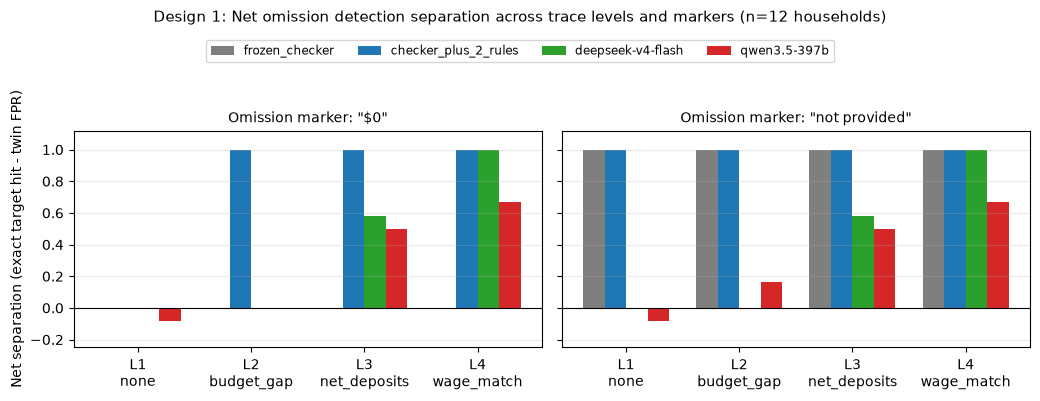

In [7]:
# Figure 1: Net separation (exact_target_hit - twin_any_fpr) across trace levels and markers
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), sharey=True)
x = np.arange(len(LEVEL_ORDER))
width = 0.19
colors = {
    "frozen_checker": "#7f7f7f",
    "checker_plus_2_rules": "#1f77b4",
    "deepseek-v4-flash": "#2ca02c",
    "qwen3.5-397b": "#d62728",
}

for ax, marker, title in zip(axes, ["$0", "not_provided"], ['Omission marker: "$0"', 'Omission marker: "not provided"']):
    for idx, reader in enumerate(READER_ORDER):
        sub = all_cells[(all_cells["reader"] == reader) & (all_cells["marker"] == marker)].set_index("trace_level").reindex(LEVEL_ORDER)
        offset = (idx - 1.5) * width
        ax.bar(x + offset, sub["net_sep_exact_vs_any_fpr"], width=width, label=reader, color=colors[reader])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, ["L1\nnone", "L2\nbudget_gap", "L3\nnet_deposits", "L4\nwage_match"])
    ax.set_ylim(-0.25, 1.12)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Net separation (exact target hit - twin FPR)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=4, fontsize=8.5, frameon=True)
fig.suptitle("Design 1: Net omission detection separation across trace levels and markers (n=12 households)", fontsize=11, y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.85])
fig.savefig(OUT / "5a-net-separation.svg", bbox_inches="tight")
plt.show()

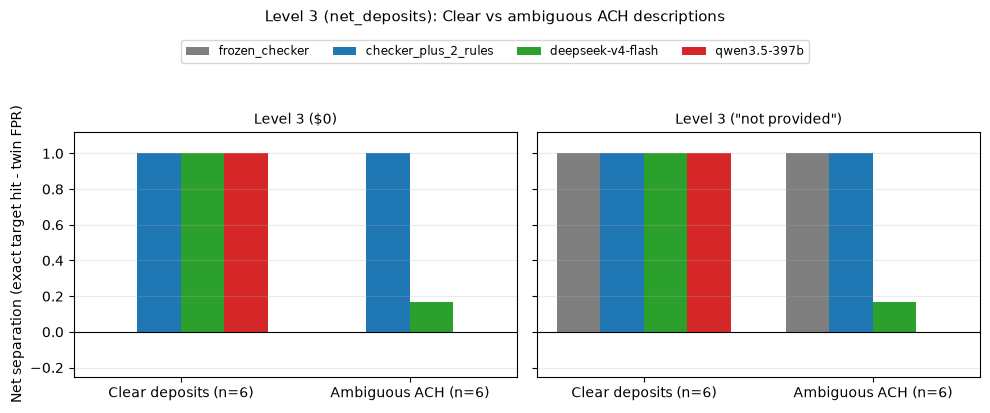

In [8]:
# Figure 2: Level 3 (net_deposits) clear vs ambiguous breakdown
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.1), sharey=True)
x = np.arange(2)
for ax, marker, title in zip(axes, ["$0", "not_provided"], ['Level 3 ($0)', 'Level 3 ("not provided")']):
    for idx, reader in enumerate(READER_ORDER):
        sub = l3_cells[(l3_cells["reader"] == reader) & (l3_cells["marker"] == marker)].set_index("subset").reindex(["clear", "ambiguous"])
        offset = (idx - 1.5) * width
        ax.bar(x + offset, sub["net_sep_exact_vs_any_fpr"], width=width, label=reader, color=colors[reader])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, ["Clear deposits (n=6)", "Ambiguous ACH (n=6)"])
    ax.set_ylim(-0.25, 1.12)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Net separation (exact target hit - twin FPR)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=4, fontsize=8.5, frameon=True)
fig.suptitle("Level 3 (net_deposits): Clear vs ambiguous ACH descriptions", fontsize=11, y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.85])
fig.savefig(OUT / "5b-level3-clear-vs-ambiguous.svg", bbox_inches="tight")
plt.show()

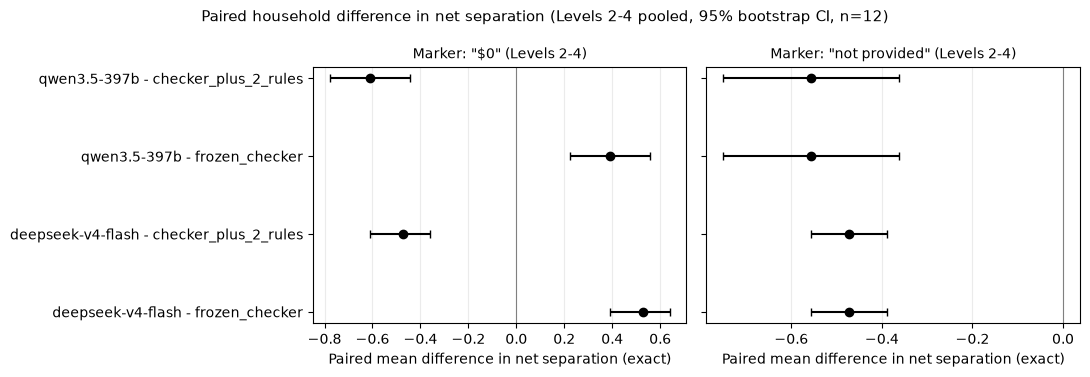

In [9]:
# Figure 3: Paired household differences on Levels 2-4 (pooled)
fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8), sharey=True)
sub_p = paired_readers_df[
    (paired_readers_df["scope"] == "levels_2_to_4")
    & (paired_readers_df["metric"] == "net_sep_exact_hit")
].copy()
for ax, marker, title in zip(axes, ["$0", "not_provided"], ['Marker: "$0" (Levels 2-4)', 'Marker: "not provided" (Levels 2-4)']):
    d = sub_p[sub_p["marker"] == marker].reset_index(drop=True)
    y = np.arange(len(d))
    ax.errorbar(
        d["mean_diff"], y,
        xerr=[d["mean_diff"] - d["ci_low"], d["ci_high"] - d["mean_diff"]],
        fmt="o", color="black", capsize=3,
    )
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_yticks(y, d["comparison"])
    ax.set_xlabel("Paired mean difference in net separation (exact)")
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("Paired household difference in net separation (Levels 2-4 pooled, 95% bootstrap CI, n=12)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "5c-paired-differences.svg", bbox_inches="tight")
plt.show()

## 6. Error Analysis: Misses, Multi-Group Flags, Twin False Flags, and Confidence

In [10]:
llm_eval = df_eval[df_eval["reader"].isin(D1.MODELS)].copy()
conf_rows = []
for r in llm_eval.itertuples():
    for g in r.flagged:
        if r.is_omission:
            kind = "target" if g == r.target_group else ("other_income" if g in ("earned", "unearned") else "non_income")
        else:
            kind = "twin_income" if g in ("earned", "unearned") else "twin_non_income"
        conf_rows.append({"reader": r.reader, "flag_kind": kind, "confidence": r.confidences.get(g)})
conf_df = pd.DataFrame(conf_rows)
if len(conf_df):
    conf_table = conf_df.groupby(["reader", "flag_kind"])["confidence"].agg(["size", "mean", "min", "max"])
    conf_table.to_csv(OUT / "6c-confidence.csv")
    display(conf_table)
misses = llm_eval[(llm_eval["is_omission"]) & (llm_eval["exact_target_hit"] == 0)]
twin_fps = llm_eval[(~llm_eval["is_omission"]) & (llm_eval["twin_any_flag"] == 1)]
other_group_on_om = llm_eval[(llm_eval["is_omission"]) & (llm_eval["any_income_hit"] == 1) & (llm_eval["exact_target_hit"] == 0)]

misses[["reader", "row", "target_group", "trace_level", "marker", "l3_clarity", "flagged", "reasons"]].to_csv(
    OUT / "6a-llm-misses.csv", index=False
)
twin_fps[["reader", "row", "target_group", "trace_level", "l3_clarity", "flagged", "reasons"]].to_csv(
    OUT / "6b-llm-twin-false-flags.csv", index=False
)

print(f"LLM exact-target misses: {len(misses)} (of which non-target income flagged: {len(other_group_on_om)})")
print(f"LLM truthful-twin false flags: {len(twin_fps)}")
if len(twin_fps):
    display(twin_fps[["reader", "row", "target_group", "trace_level", "l3_clarity", "flagged", "reasons"]])
if len(other_group_on_om):
    print("Misses on exact target where the OTHER income group was flagged instead:")
    display(other_group_on_om[["reader", "row", "target_group", "trace_level", "marker", "flagged", "reasons"]])

size      mean   min   max
reader            flag_kind                                  
deepseek-v4-flash other_income        8  0.775000  0.40  0.90
                  target             46  0.854783  0.60  0.98
                  twin_income         4  0.575000  0.50  0.60
qwen3.5-397b      non_income         13  0.626923  0.50  0.70
                  other_income        8  0.762500  0.40  0.90
                  target             46  0.875000  0.35  0.95
                  twin_income         5  0.600000  0.35  0.75
                  twin_non_income    10  0.625000  0.50  0.90

LLM exact-target misses: 100 (of which non-target income flagged: 7)
LLM truthful-twin false flags: 13


,reader,row,target_group,trace_level,l3_clarity,flagged,reasons
341,qwen3.5-397b,14542,earned,wage_match,clear,"[shelter, utilities]",shelter: Reported $0 shelter costs with no doc...
374,deepseek-v4-flash,42865,earned,net_deposits,ambiguous,[unearned],unearned: Reported $0 unearned income but bank...
385,qwen3.5-397b,42865,earned,wage_match,ambiguous,"[shelter, utilities]",shelter: Shelter costs reported as $0 with no ...
406,qwen3.5-397b,42777,earned,wage_match,ambiguous,"[shelter, utilities]",shelter: Reported $0 shelter costs is unusual ...
494,qwen3.5-397b,43456,unearned,net_deposits,ambiguous,[unearned],unearned: Bank records show $156.78 ACH credit...
498,deepseek-v4-flash,43456,unearned,net_deposits,ambiguous,[unearned],unearned: Bank shows an unexplained $156.78 AC...
518,deepseek-v4-flash,41978,unearned,net_deposits,ambiguous,[unearned],unearned: Bank records show an unexplained $24...
521,qwen3.5-397b,28066,unearned,none,clear,"[earned, shelter, utilities]",earned: Reported $382 monthly earned income do...
524,qwen3.5-397b,41978,unearned,net_deposits,ambiguous,[unearned],unearned: ACH credit of $243.14 in bank record...
555,qwen3.5-397b,34791,unearned,wage_match,ambiguous,"[shelter, utilities]",shelter: Reported $0 shelter costs is unusual ...


Misses on exact target where the OTHER income group was flagged instead:


,reader,row,target_group,trace_level,marker,flagged,reasons
345,qwen3.5-397b,14542,earned,budget_gap,not_provided,[unearned],unearned: Reported $0 unearned income contradi...
499,qwen3.5-397b,43456,unearned,net_deposits,$0,[earned],earned: Two identical monthly ACH electronic d...
505,qwen3.5-397b,43456,unearned,net_deposits,not_provided,[earned],earned: Two monthly ACH electronic deposits of...
510,deepseek-v4-flash,41978,unearned,net_deposits,$0,[earned],earned: Recurring monthly ACH credit deposits ...
542,deepseek-v4-flash,34791,unearned,net_deposits,not_provided,[earned],"earned: Two recurring $1,572 ACH electronic de..."
543,qwen3.5-397b,34791,unearned,net_deposits,$0,[earned],earned: Two recurring monthly ACH CREDIT ELECT...
547,qwen3.5-397b,34791,unearned,net_deposits,not_provided,[earned],earned: Two recurring monthly ACH CREDIT ELECT...
